<a href="https://colab.research.google.com/github/Jose-Luan/hate_speech_classification_tcc/blob/main/codigo/fine-tuning/BERTurgues.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install transformers dataset torch scikit-learn evaluate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 19.0 MB/s eta 0:00:00
  Attempting uninstall: sqlalchemy
    Found existing installation: SQLAlchemy 2.0.43
    Uninstalling SQLAlchemy-2.0.43:
      Successfully uninstalled SQLAlchemy-2.0.43
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.14.1 requires sqlalchemy<3.0.0,>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.
ipython-sql 0.5.0 requires sqlalchemy>=2.0, but you have sqlalchemy 1.4.54 which is incompatible.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from datasets import load_dataset, Dataset, DatasetDict
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
)
import evaluate
import os

In [22]:
def save_metrics_and_plots(results, y_true, y_pred, output_dir, model_name):
    """
    Salva métricas globais, matriz de confusão e relatório de classificação.
    """
    os.makedirs(output_dir, exist_ok=True)

    # Salvar métricas globais
    results_df = pd.DataFrame([results]).round(3) * 100
    results_df.to_csv(f"{output_dir}/metrics5.csv", index=False)

    # Matriz de Confusão
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Não Ódio (0)", "Ódio (1)"],
        yticklabels=["Não Ódio (0)", "Ódio (1)"]
    )
    plt.xlabel("Predito")
    plt.ylabel("Real")
    plt.title(f"Matriz de Confusão - {model_name}")
    plt.tight_layout()
    plt.savefig(f"{output_dir}/confusion_matrix5.png")
    plt.close()

    # Classification Report
    report = classification_report(
        y_true,
        y_pred,
        target_names=["Não Ódio (0)", "Ódio (1)"],
    )
    with open(f"{output_dir}/classification_report5.txt", "w", encoding="utf-8") as f:
        f.write(report)

    print(f"\n✅ Resultados salvos em '{output_dir}'")


def plot_confusion(y_true, y_pred, titulo, path):
    """
    Plota a matriz de confusão e salva o relatório de classificação.
    """
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Não ódio (0)", "Ódio (1)"],
                yticklabels=["Não ódio (0)", "Ódio (1)"])
    plt.xlabel("Predição")
    plt.ylabel("Real")
    plt.title(titulo)
    plt.show()

    report = classification_report(y_true, y_pred, target_names=["Não ódio (0)", "Ódio (1)"])

    print("\nRelatório de Classificação:")
    print(report)

def evaluate_and_predict(trainer, tokenized_dataset,titulo):
    """
    Avalia o modelo no conjunto de teste, faz predições e retorna os resultados e predições.
    """
    #1)Avaliação com métricas globais
    results = trainer.evaluate(tokenized_dataset["test"])
    results_df = pd.DataFrame([results])
    print("📊 "+titulo+"\n")
    print(results_df.to_markdown(index=False))

    #2)Predições para matriz de confusão e relatório
    predictions = trainer.predict(tokenized_dataset["test"])
    y_true = predictions.label_ids
    y_pred = np.argmax(predictions.predictions, axis=-1)

    results_df = results_df[['eval_accuracy','eval_f1_macro','eval_recall_macro','eval_precision_macro']].round(3)*100
    results_df.to_csv('/content/hate_speech_classification_tcc/resultados/bert/berturgues/results_berturgues.csv', index=False)

    return results, y_true, y_pred, results_df

In [8]:
#carregar base de dados de teste ,treino e validação
df_train = pd.read_csv('/content/hate_speech_classification_tcc/dados/HateBR/train.csv')
df_val = pd.read_csv('/content/hate_speech_classification_tcc/dados/HateBR/validation.csv')
df_test = pd.read_csv('/content/hate_speech_classification_tcc/dados/Portuguese_Hate_Speech_Dataset/test.csv')

In [9]:
# Convert pandas DataFrames to Dataset objects
dataset = DatasetDict({
    'train': Dataset.from_pandas(df_train),
    'validation': Dataset.from_pandas(df_val),
    'test': Dataset.from_pandas(df_test)
})
dataset

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 4500
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 500
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 200
    })
})

# Carregando o modelo BERTurgues e Tokenização

In [10]:
model_name = "ricardoz/BERTugues-base-portuguese-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)

def tokenize_batch(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)

tokenized_dataset = dataset.map(tokenize_batch, batched=True)

tokenized_dataset = tokenized_dataset.remove_columns(["text"])
tokenized_dataset = tokenized_dataset.rename_column("label", "labels")
tokenized_dataset.set_format("torch")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/4500 [00:00<?, ? examples/s]

Map:   0%|          | 0/500 [00:00<?, ? examples/s]

Map:   0%|          | 0/200 [00:00<?, ? examples/s]

In [11]:
model = AutoModelForSequenceClassification.from_pretrained(model_name, num_labels=2)

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at ricardoz/BERTugues-base-portuguese-cased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [12]:
# Inspeção de camadas
for name, param in model.named_parameters():
    print(name, param.requires_grad)

for param in model.base_model.embeddings.parameters():
    param.requires_grad = False

bert.embeddings.word_embeddings.weight True
bert.embeddings.position_embeddings.weight True
bert.embeddings.token_type_embeddings.weight True
bert.embeddings.LayerNorm.weight True
bert.embeddings.LayerNorm.bias True
bert.encoder.layer.0.attention.self.query.weight True
bert.encoder.layer.0.attention.self.query.bias True
bert.encoder.layer.0.attention.self.key.weight True
bert.encoder.layer.0.attention.self.key.bias True
bert.encoder.layer.0.attention.self.value.weight True
bert.encoder.layer.0.attention.self.value.bias True
bert.encoder.layer.0.attention.output.dense.weight True
bert.encoder.layer.0.attention.output.dense.bias True
bert.encoder.layer.0.attention.output.LayerNorm.weight True
bert.encoder.layer.0.attention.output.LayerNorm.bias True
bert.encoder.layer.0.intermediate.dense.weight True
bert.encoder.layer.0.intermediate.dense.bias True
bert.encoder.layer.0.output.dense.weight True
bert.encoder.layer.0.output.dense.bias True
bert.encoder.layer.0.output.LayerNorm.weight True


In [13]:
accuracy = evaluate.load("accuracy")
precision = evaluate.load("precision")
recall = evaluate.load("recall")
f1 = evaluate.load("f1")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy.compute(predictions=preds, references=labels)["accuracy"],
        "precision_macro": precision.compute(predictions=preds, references=labels, average="macro")["precision"],
        "recall_macro": recall.compute(predictions=preds, references=labels, average="macro")["recall"],
        "f1_macro": f1.compute(predictions=preds, references=labels, average="macro")["f1"],
        "f1_weighted": f1.compute(predictions=preds, references=labels, average="weighted")["f1"],
    }

In [18]:
# Configuração do treinamento
training_args = TrainingArguments(
    output_dir="./berturgues-results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=5,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    report_to="none",
)

data_collator = DataCollatorWithPadding(tokenizer)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics,
)

In [15]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,No log,0.205456,0.920000,0.911706,0.895238,0.902865,0.919184
2,0.243200,0.327762,0.910000,0.911117,0.870952,0.887652,0.907695
3,0.243200,0.333032,0.914000,0.902049,0.890952,0.896211,0.913398


TrainOutput(global_step=846, training_loss=0.1870724968876399, metrics={'train_runtime': 333.4594, 'train_samples_per_second': 40.485, 'train_steps_per_second': 2.537, 'total_flos': 887999811840000.0, 'train_loss': 0.1870724968876399, 'epoch': 3.0})

In [21]:
results, y_true, y_pred, results_df = evaluate_and_predict(trainer, tokenized_dataset,"Resultados Globais no Teste(BERTurgues) 3 epocas:")
print("\n",results_df.head())


📊 Resultados Globais no Teste(BERTurgues) 3 epocas:

|   eval_loss |   eval_model_preparation_time |   eval_accuracy |   eval_precision_macro |   eval_recall_macro |   eval_f1_macro |   eval_f1_weighted |   eval_runtime |   eval_samples_per_second |   eval_steps_per_second |
|------------:|------------------------------:|----------------:|-----------------------:|--------------------:|----------------:|-------------------:|---------------:|--------------------------:|------------------------:|
|    0.879024 |                        0.0028 |           0.725 |               0.676638 |            0.684524 |            0.68 |              0.728 |         1.4039 |                   142.461 |                    9.26 |

    eval_accuracy  eval_f1_macro  eval_recall_macro  eval_precision_macro
0           72.5           68.0               68.5                  67.7



✅ Resultados salvos em '/content/hate_speech_classification_tcc/resultados/bert/berturgues'


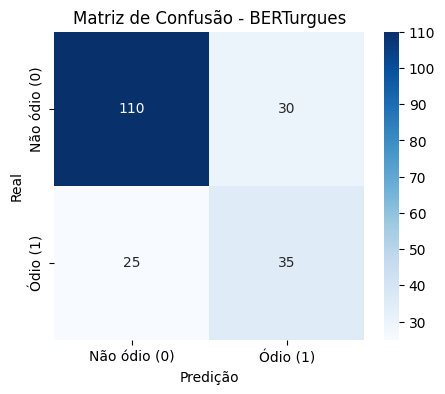


Relatório de Classificação:
              precision    recall  f1-score   support

Não ódio (0)       0.81      0.79      0.80       140
    Ódio (1)       0.54      0.58      0.56        60

    accuracy                           0.72       200
   macro avg       0.68      0.68      0.68       200
weighted avg       0.73      0.72      0.73       200



In [23]:
# 2) Salvar métricas, matriz de confusão e relatório
save_metrics_and_plots(
    results=results,
    y_true=y_true,
    y_pred=y_pred,
    output_dir="/content/hate_speech_classification_tcc/resultados/bert/berturgues",
    model_name="BERTimbau-Large"
)

plot_confusion(y_true, y_pred, "Matriz de Confusão - BERTurgues", "/content/hate_speech_classification_tcc/resultados/bert/berturgues")

In [24]:
trainer.train()

Epoch,Training Loss,Validation Loss,Model Preparation Time,Accuracy,Precision Macro,Recall Macro,F1 Macro,F1 Weighted
1,No log,0.356671,0.002800,0.918000,0.908443,0.893810,0.900639,0.917252
2,0.122200,0.455376,0.002800,0.908000,0.909558,0.867619,0.884899,0.905525
3,0.122200,0.532494,0.002800,0.916000,0.906746,0.890476,0.898009,0.915143
4,0.047200,0.605393,0.002800,0.914000,0.897066,0.898571,0.897813,0.914081
5,0.047200,0.633753,0.002800,0.910000,0.892322,0.893810,0.893060,0.910085


TrainOutput(global_step=1410, training_loss=0.06251553356224764, metrics={'train_runtime': 736.4661, 'train_samples_per_second': 30.551, 'train_steps_per_second': 1.915, 'total_flos': 1479999686400000.0, 'train_loss': 0.06251553356224764, 'epoch': 5.0})

In [26]:
results, y_true, y_pred, results_df = evaluate_and_predict(trainer, tokenized_dataset,"Resultados Globais no Teste(BERTurgues) 5 epocas:")
print("\n",results_df.head())

📊 Resultados Globais no Teste(BERTurgues) 5 epocas:

|   eval_loss |   eval_model_preparation_time |   eval_accuracy |   eval_precision_macro |   eval_recall_macro |   eval_f1_macro |   eval_f1_weighted |   eval_runtime |   eval_samples_per_second |   eval_steps_per_second |   epoch |
|------------:|------------------------------:|----------------:|-----------------------:|--------------------:|----------------:|-------------------:|---------------:|--------------------------:|------------------------:|--------:|
|     1.51105 |                        0.0028 |           0.705 |               0.651778 |            0.655952 |        0.653664 |              0.707 |         1.6464 |                   121.474 |                   7.896 |       5 |

    eval_accuracy  eval_f1_macro  eval_recall_macro  eval_precision_macro
0           70.5           65.4               65.6                  65.2



✅ Resultados salvos em '/content/hate_speech_classification_tcc/resultados/bert/berturgues/'


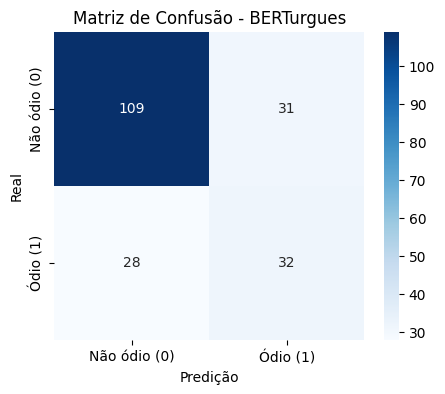


Relatório de Classificação:
              precision    recall  f1-score   support

Não ódio (0)       0.80      0.78      0.79       140
    Ódio (1)       0.51      0.53      0.52        60

    accuracy                           0.70       200
   macro avg       0.65      0.66      0.65       200
weighted avg       0.71      0.70      0.71       200



In [27]:
# 2) Salvar métricas, matriz de confusão e relatório
save_metrics_and_plots(
    results=results,
    y_true=y_true,
    y_pred=y_pred,
    output_dir="/content/hate_speech_classification_tcc/resultados/bert/berturgues/",
    model_name="BERTimbau-Large"
)

plot_confusion(y_true, y_pred, "Matriz de Confusão - BERTurgues", "/content/hate_speech_classification_tcc/resultados/bert/berturgues/")